# Trustworthy Experiments (SRM, A-A Tests & Guardrails)

A p-value is correct only if the experiment itself is correct. A logging bug, a wrong randomization unit or a missing
metric can produce a significant result that is false. Experienced teams therefore check the experiment before they
read the effect. Kohavi, Tang and Xu describe these checks in the book *Trustworthy Online Controlled Experiments*
(2020).

This lesson implements three important checks on the Hillstrom e-mail test. They are the sample ratio test, the
A/A test and the guardrail metric with a non-inferiority test.

**After this lesson you can:**

1. Detect a **sample ratio mismatch** (SRM) with a chi-square test, and explain why it invalidates the effect.
2. Run 2,000 A/A tests with vectorised NumPy and check that the p-values are uniform.
3. Recognise two causes of a failed A/A test: a unit mismatch and heavy tails at small sample sizes.
4. Test a guardrail metric with a one-sided non-inferiority test and a margin.
5. Describe novelty, primacy and interference effects, and use a trustworthiness checklist.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
Section 2 creates a clearly labelled corrupted copy of the data to show a logging bug.
**Services:** none.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", category=RuntimeWarning)   # t-tests on all-zero samples return NaN (section 5)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
print(df.segment.value_counts().to_string())
print(f"total: {len(df):,} customers | designed split: 1/3 for each arm")

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
total: 64,000 customers | designed split: 1/3 for each arm


## 1. Sample Ratio Mismatch

The design of the test fixes the share of users in each arm: here one third each. A **sample ratio mismatch** (SRM)
is a difference between the designed shares and the observed counts that is too large for chance. An SRM means
that something removed or added users in one arm after the randomization. Then the arms are no longer comparable,
and the effect estimate can have any bias.

The **SRM test** is a chi-square goodness-of-fit test of the observed counts $O_k$ against the expected counts $E_k$:

$$\chi^2 = \sum_{k=1}^{K} \frac{(O_k - E_k)^2}{E_k}, \qquad \text{degrees of freedom} = K - 1 .$$

The test needs no outcome data, so run it first. Many platforms use a strict threshold such as $p < 0.001$,
because they run the test on every experiment and a false alarm stops the analysis.

In [2]:
import tea_tasting as tt

counts = df.segment.value_counts().sort_index()
chi2, p = stats.chisquare(counts.values)              # expected: equal counts in all arms
print(f"3 arms: chi2 = {chi2:.3f}, p = {p:.3f}")

# the same check for one pair, with tea-tasting (lesson 03)
pair = df[df.segment.isin(["Mens E-Mail", "No E-Mail"])].assign(variant=lambda x: x.segment)
res = tt.Experiment(sample_ratio=tt.SampleRatio()).analyze(pair, control="No E-Mail")
print(res.to_pandas()[["metric", "control", "treatment", "pvalue"]].round(3).to_string(index=False))

3 arms: chi2 = 0.203, p = 0.904
      metric  control  treatment  pvalue
sample_ratio    21306      21307     1.0


The real data passes the test: $\chi^2 = 0.203$ with $p = 0.904$. The largest arm has only 81 more customers than
the smallest arm. For the pair, tea-tasting gives $p = 1.0$, because the two counts differ by only one customer.

## 2. A Logging Bug Creates an SRM

The next cell creates a **corrupted copy** of the data. It is not real data. It simulates a common bug. The
treatment arm logs users through a new e-mail tracking pipeline. This pipeline loses 10 % of the users who never
visited the site.

The control arm has no such loss. Such bugs are realistic: for example, a bot filter or a
redirect can remove users in one arm only.

The users who disappear are the users without a visit. So the treatment arm looks better than it is.

In [3]:
def corrupt(data, drop_share, seed=6):
    # remove drop_share of the treatment users who did not visit (the simulated logging bug)
    rng = np.random.default_rng(seed)
    lost = (data.segment == "Mens E-Mail") & (data.visit == 0) & (rng.random(len(data)) < drop_share)
    return data[~lost]

def srm_and_lift(data):
    n_t, n_c = (data.segment == "Mens E-Mail").sum(), (data.segment == "No E-Mail").sum()
    p_srm = stats.chisquare([n_t, n_c]).pvalue
    rates = data.groupby("segment").visit.mean()
    return n_t, n_c, p_srm, rates["Mens E-Mail"] - rates["No E-Mail"]

two = df[df.segment.isin(["Mens E-Mail", "No E-Mail"])]
bad = corrupt(two, 0.10)
for name, data in [("real data", two), ("corrupted copy (10 % bug)", bad)]:
    n_t, n_c, p_srm, lift = srm_and_lift(data)
    print(f"{name:25s}: treatment {n_t:,} | control {n_c:,} | SRM p = {p_srm:.2e} | visit lift {100 * lift:.2f} pp")

real data                : treatment 21,307 | control 21,306 | SRM p = 9.96e-01 | visit lift 7.66 pp
corrupted copy (10 % bug): treatment 19,588 | control 21,306 | SRM p = 1.97e-17 | visit lift 9.26 pp


The bug removes 1,719 treatment users (8 % of the arm), and the SRM test reports $p = 2 \cdot 10^{-17}$. The visit lift
grows from 7.66 to 9.26 percentage points: a bias of 1.6 percentage points, or 21 % of the true effect. Without the SRM test,
the team would report the wrong number with a narrow confidence interval and a small p-value.

Do not "correct" an SRM by reweighting the arms. The missing users differ from the other users, and the analysis
cannot know how. Find the cause, fix it, and rerun the experiment.

## 3. How Small a Loss Can the SRM Test Detect?

The cell repeats the corruption with loss rates from 0 % to 10 % of the non-visitors. For each loss rate it
prints the SRM p-value and the bias of the visit lift.

In [4]:
grid = []
for share in [0, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.07, 0.10]:
    n_t, n_c, p_srm, lift = srm_and_lift(corrupt(two, share))
    grid.append({"lost_share_%": 100 * share, "users_lost": int((two.segment == "Mens E-Mail").sum() - n_t),
                 "SRM_p": p_srm, "visit_lift_pp": 100 * lift})
grid = pd.DataFrame(grid)
grid["bias_pp"] = grid.visit_lift_pp - grid.visit_lift_pp[0]
print(grid.to_string(index=False, formatters={"SRM_p": "{:.2e}".format, "visit_lift_pp": "{:.2f}".format,
                                               "bias_pp": "{:.2f}".format}))

 lost_share_%  users_lost    SRM_p visit_lift_pp bias_pp
          0.0           0 9.96e-01          7.66    0.00
          0.5          91 6.63e-01          7.74    0.08
          1.0         170 4.12e-01          7.81    0.15
          2.0         333 1.06e-01          7.95    0.29
          3.0         505 1.40e-02          8.10    0.44
          4.0         659 1.32e-03          8.24    0.58
          5.0         830 5.00e-05          8.40    0.74
          7.0        1179 7.16e-09          8.73    1.07
         10.0        1719 1.97e-17          9.26    1.60


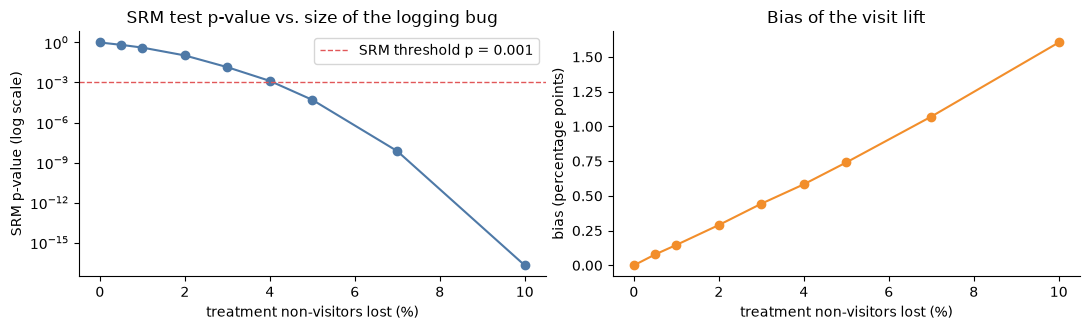

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].semilogy(grid["lost_share_%"], grid.SRM_p, marker="o", color="#4E79A7")
ax[0].axhline(0.001, color="#E15759", ls="--", lw=1, label="SRM threshold p = 0.001")
ax[0].set(title="SRM test p-value vs. size of the logging bug", xlabel="treatment non-visitors lost (%)",
          ylabel="SRM p-value (log scale)")
ax[0].legend()
ax[1].plot(grid["lost_share_%"], grid.bias_pp, marker="o", color="#F28E2B")
ax[1].set(title="Bias of the visit lift", xlabel="treatment non-visitors lost (%)",
          ylabel="bias (percentage points)")
plt.tight_layout(); plt.show()

With about 21,000 users per arm, the test crosses $p < 0.001$ between 659 and 830 lost users. This is 3 to 4 % of
the treatment arm. A smaller loss passes the test, but it still biases the lift. Take a loss of 3 % of the
non-visitors: the SRM p-value is 0.014, and the bias is 0.44 points (6 % of the effect). Larger experiments detect smaller losses, because the chi-square statistic
grows with the number of users.

*Insight: The SRM test is cheap and needs no outcome data. But it has low power: here it detects only a loss of
3 to 4 % of one arm or more. An experiment that fails the SRM test has no valid effect estimate. An experiment that passes it
can still have a small bias.*

## 4. A/A Tests

An **A/A test** compares two groups that get the same experience. The true effect is zero, so:

1. The test rejects $H_0$ in about $\alpha = 5\,\%$ of A/A tests (the **false positive rate**, FPR).
2. The p-values follow a uniform distribution on $[0, 1]$. Each bin of a histogram holds about the same number.

A platform runs A/A tests to check its full pipeline: assignment, logging, metric computation and statistics. Here,
the cell splits the 21,306 real "No E-Mail" users at random into two halves, 2,000 times. Each split is one A/A
test. A matrix product computes the sums of all 2,000 splits at once, and a Welch z-test gives the p-value.

In [6]:
control = df[df.segment == "No E-Mail"].reset_index(drop=True)

def welch_p(s1, ss1, n1, s0, ss0, n0):
    # two-sided Welch z-test from sums and sums of squares
    m1, m0 = s1 / n1, s0 / n0
    v1, v0 = (ss1 - n1 * m1**2) / (n1 - 1), (ss0 - n0 * m0**2) / (n0 - 1)
    return 2 * stats.norm.sf(np.abs(m1 - m0) / np.sqrt(v1 / n1 + v0 / n0))

def aa_user_split(y, n_sims=2000, seed=0, batch=250):
    # n_sims random 50/50 user splits of the same users -> p-values
    y = np.array(y, dtype=float); n = len(y); n1 = n // 2
    rng = np.random.default_rng(seed)
    vec, tot = np.column_stack([y, y**2]), np.array([y.sum(), (y**2).sum()])
    p = []
    for b in range(0, n_sims, batch):
        A = np.zeros((min(batch, n_sims - b), n))
        np.put_along_axis(A, np.argsort(rng.random(A.shape), axis=1)[:, :n1], 1.0, axis=1)
        S = A @ vec
        p.append(welch_p(S[:, 0], S[:, 1], n1, tot[0] - S[:, 0], tot[1] - S[:, 1], n - n1))
    return np.concatenate(p)

aa = {m: aa_user_split(control[m], seed=i) for i, m in enumerate(["visit", "spend"])}
for m, p in aa.items():
    print(f"A/A on {m:5s}: FPR at 0.05 = {100 * (p < 0.05).mean():.2f} % | "
          f"KS test of uniformity p = {stats.kstest(p, 'uniform').pvalue:.3f}")

A/A on visit: FPR at 0.05 = 4.50 % | KS test of uniformity p = 0.029
A/A on spend: FPR at 0.05 = 4.55 % | KS test of uniformity p = 0.877


Both metrics pass the main check: the FPR is 4.50 % for `visit` and 4.55 % for `spend`. The Kolmogorov-Smirnov
(KS) test of uniformity gives $p = 0.877$ for `spend` and $p = 0.029$ for `visit`. The small KS p-value for `visit`
comes from discreteness. A 0/1 metric has integer sums, so its p-values take only some values, and the histogram in
section 5 has uneven bins. With 2,000 A/A tests, the FPR has a standard error of
$\sqrt{0.05 \cdot 0.95 / 2000} \approx 0.5$ percentage points, so values between 4 % and 6 % are normal.

## 5. What Breaks an A/A Test

### 5.1 Unit mismatch

The **randomization unit** is the thing that the platform assigns: a user, a session, a city. The **analysis unit**
is the row in the t-test. If the platform randomizes groups of users but the analysis treats every user as
independent, the standard error is too small. Users in the same group are similar, so they do not give independent
information.

The cell simulates this mistake with the real users. It forms 57 groups from the combinations of `history_segment`,
`zip_code` and `channel`, and assigns whole groups to A or B. This is like a test that randomizes by region or
store. Then it runs two analyses:

1. **Wrong:** a per-user Welch test, as if the platform had randomized users.
2. **Correct:** the delta method for the ratio metric "visits / users" per group (lesson 04), with the group as unit.

In [7]:
codes, groups = pd.factorize(control.history_segment + "|" + control.zip_code + "|" + control.channel)
G = len(groups)
S = np.bincount(codes, weights=control.visit.to_numpy(dtype=float), minlength=G)   # visits per group
N = np.bincount(codes, minlength=G).astype(float)                                   # users per group
print(f"{G} groups | users per group: min {N.min():.0f}, median {np.median(N):.0f}, max {N.max():.0f}")
print(f"visit rate per group: min {(S / N).min():.3f}, max {(S / N).max():.3f}")

def delta_ratio(B, S, N):
    # mean ratio sum(S)/sum(N) of the groups selected by the 0/1 rows of B, and its delta-method variance
    m = B.sum(axis=1)
    sS, sN = B @ S, B @ N
    vS = (B @ S**2 - sS**2 / m) / (m - 1); vN = (B @ N**2 - sN**2 / m) / (m - 1)
    cSN = (B @ (S * N) - sS * sN / m) / (m - 1)
    R, Nbar = sS / sN, sN / m
    return R, (vS - 2 * R * cSN + R**2 * vN) / (m * Nbar**2)

rng = np.random.default_rng(5)
B = np.zeros((2000, G))                                     # 1 = group in arm B
np.put_along_axis(B, np.argsort(rng.random((2000, G)), axis=1)[:, :G // 2], 1.0, axis=1)
# wrong analysis: users are rows, but the arms come from the group assignment
sum_b, ss_b, n_b = B @ S, B @ S, B @ N                      # visit is 0/1, so y^2 = y
p_user = welch_p(sum_b, ss_b, n_b, S.sum() - sum_b, S.sum() - ss_b, N.sum() - n_b)
# correct analysis: groups are the units (delta method)
R1, V1 = delta_ratio(B, S, N); R0, V0 = delta_ratio(1 - B, S, N)
p_group = 2 * stats.norm.sf(np.abs(R1 - R0) / np.sqrt(V1 + V0))
print(f"per-user Welch test (wrong):  FPR = {100 * (p_user < 0.05).mean():.1f} %")
print(f"group-level delta method:     FPR = {100 * (p_group < 0.05).mean():.1f} %")

57 groups | users per group: min 21, median 234, max 1767
visit rate per group: min 0.000, max 0.269
per-user Welch test (wrong):  FPR = 51.2 %
group-level delta method:     FPR = 8.4 %


The visit rate differs strongly between the groups (from 0.000 to 0.269). Thus the assignment of a few large groups
decides most of the difference between the arms. The per-user test ignores this and rejects $H_0$ in 51.2 % of the A/A tests:
ten times the designed 5 %. The delta method with groups as units brings the FPR back to 8.4 %. It is still
above 5 %, because the delta method is a large-sample approximation and here it has only 28 or 29 groups per arm.

**Rule:** analyse at the randomization unit, or use a variance formula that accounts for it (delta method,
cluster-robust standard errors).

### 5.2 Heavy tails at small sample sizes

The Welch test assumes that the mean is approximately normal. For `spend` this needs many users: about 99 % of the
users spend $0, and a few spend up to $499. The cell runs 2,000 A/A tests with the real `spend` values at small
and large sample sizes.

In [8]:
y = control.spend.to_numpy(dtype=float)
print(f"share of users with spend > 0: {100 * (y > 0).mean():.2f} %")
small = []
rng = np.random.default_rng(9)
p_small = {}
for n in [50, 200, 1000, 5000]:
    idx = np.stack([rng.choice(len(y), 2 * n, replace=False) for _ in range(2000)])
    p = stats.ttest_ind(y[idx[:, :n]], y[idx[:, n:]], axis=1, equal_var=False).pvalue
    p_small[n] = p
    small.append({"n_per_arm": n, "no_test_possible_%": 100 * np.isnan(p).mean(),
                  "FPR_%": 100 * (np.nan_to_num(p, nan=1.0) < 0.05).mean()})
print(pd.DataFrame(small).round(2).to_string(index=False))

share of users with spend > 0: 0.57 %


 n_per_arm  no_test_possible_%  FPR_%
        50               55.65   0.05
       200               10.20   0.15
      1000                0.00   3.15
      5000                0.00   5.00


At 50 users per arm, 56 % of the A/A tests have no buyer in either arm. Then the t-test cannot compute a p-value
(NaN). Where it can, it almost never rejects: the FPR is 0.05 % at 50 and 0.15 % at 200 users per arm. The test is
**invalid in the other direction**: it is too conservative, so it also has almost no power. At 1,000 users per arm the FPR is
3.15 %, and at 5,000 it is 5.00 %. For a sparse, heavy-tailed metric, plan the sample size for the metric and
check it with an A/A simulation like this one.

Many tests with 200 users per arm have exactly one buyer in total. For each of them the t-statistic is exactly 1, so
$p \approx 0.32$. The plot shows this spike, together with the other p-value histograms of this lesson.

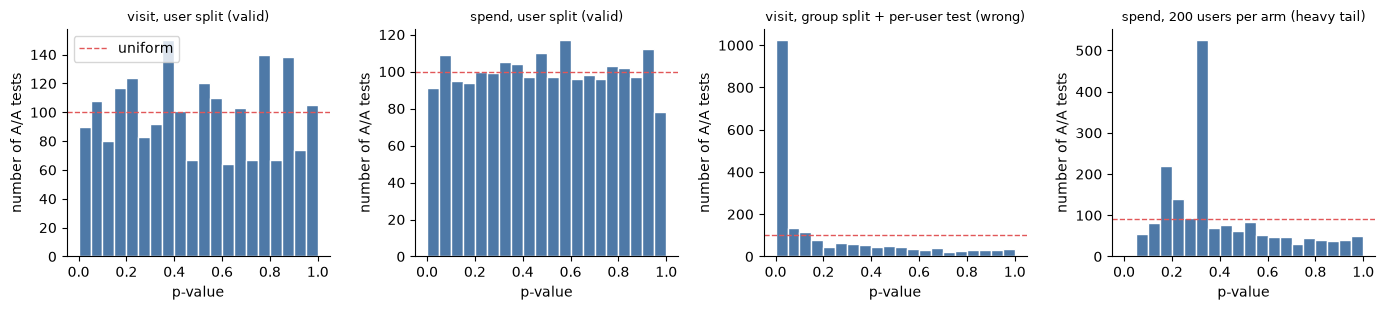

In [9]:
panels = [("visit, user split (valid)", aa["visit"]), ("spend, user split (valid)", aa["spend"]),
          ("visit, group split + per-user test (wrong)", p_user),
          ("spend, 200 users per arm (heavy tail)", p_small[200][~np.isnan(p_small[200])])]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=False)
for a, (title, p) in zip(ax, panels):
    a.hist(p, bins=20, range=(0, 1), color="#4E79A7", edgecolor="white")
    a.axhline(len(p) / 20, color="#E15759", ls="--", lw=1, label="uniform")
    a.set(title=title, xlabel="p-value", ylabel="number of A/A tests")
    a.title.set_fontsize(9)
ax[0].legend()
plt.tight_layout(); plt.show()

*Insight: A valid A/A test gives a flat p-value histogram. A peak at small p-values means false positives, here from
the unit mismatch. A peak at large or fixed p-values means a test without power, here from the heavy tail.*

## 6. Guardrail Metrics and Non-Inferiority Tests

A **guardrail metric** is a metric that the treatment must not harm, even if it is not the goal of the
experiment. Examples: page load time, unsubscribe rate, crash rate, revenue of an important segment. A
non-significant two-sided test does **not** show that there is no harm. It can mean that the test had too little
power.

The correct test is a **non-inferiority test**. It needs a **margin** $m > 0$: the largest loss that the business
accepts. With the effect $\Delta = \mu_T - \mu_C$:

$$H_0: \Delta \le -m \qquad \text{vs.} \qquad H_1: \Delta > -m, \qquad
z = \frac{\hat\Delta + m}{\operatorname{SE}(\hat\Delta)}, \qquad p = 1 - \Phi(z) .$$

An equal rule: the guardrail passes at $\alpha = 0.05$ if the lower bound of the one-sided 95 % confidence
interval, $\hat\Delta - 1.645\,\operatorname{SE}$, is above $-m$.

The cell checks two guardrails. The margins are **assumptions** of this lesson, not values from Hillstrom:

1. The e-mail must not lower the visit rate of **newbies** by more than 1 percentage point.
2. The women's e-mail must not lower the conversion rate of **rural** customers by more than 0.05 percentage points.

In [10]:
def non_inferiority(data, treatment, metric, margin, alpha=0.05):
    t = data.loc[data.segment == treatment, metric]
    c = data.loc[data.segment == "No E-Mail", metric]
    est = t.mean() - c.mean()
    se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    return {"treatment": treatment, "metric": metric, "n_T": len(t), "n_C": len(c), "effect_pp": 100 * est,
            "margin_pp": 100 * margin, "lower_bound_pp": 100 * (est - stats.norm.ppf(1 - alpha) * se),
            "p_two_sided": 2 * stats.norm.sf(abs(est / se)), "p_non_inferiority": stats.norm.sf((est + margin) / se)}

checks = pd.DataFrame([
    non_inferiority(df[df.newbie == 1], "Mens E-Mail", "visit", 0.01),
    non_inferiority(df[df.newbie == 1], "Womens E-Mail", "visit", 0.01),
    non_inferiority(df[df.zip_code == "Rural"], "Womens E-Mail", "conversion", 0.0005)])
checks["guardrail"] = np.where(checks.p_non_inferiority < 0.05, "pass", "not shown")
print(checks.round(4).to_string(index=False))

    treatment     metric   n_T   n_C  effect_pp  margin_pp  lower_bound_pp  p_two_sided  p_non_inferiority guardrail
  Mens E-Mail      visit 10686 10695     7.5305       1.00          6.8137       0.0000             0.0000      pass
Womens E-Mail      visit 10763 10695     5.0417       1.00          4.3586       0.0000             0.0000      pass
Womens E-Mail conversion  3181  3139     0.3349       0.05         -0.0758       0.1798             0.0616 not shown


The two newbie guardrails pass with a large distance. The visit rate rises by 7.5 and 5.0 percentage points. The
lower bounds (6.8 and 4.4) are far above $-1$.

The rural conversion guardrail shows the trap. The two-sided test gives $p = 0.18$: "no significant difference".
But the lower bound of the effect is $-0.08$ percentage points, below the margin of $-0.05$, and the non-inferiority p-value is 0.062. The data cannot exclude
a loss larger than the margin, so non-inferiority is **not shown**. About 3,200 users per arm are too few to test
such a small margin.

| question | test | pass rule |
| :--- | :--- | :--- |
| Did the treatment improve the goal metric? | two-sided (or one-sided superiority) | $p < \alpha$ and lift in the right direction |
| Is the treatment not worse than the control by more than $m$? | non-inferiority, one-sided | lower bound of the one-sided CI $> -m$ |
| Is the experiment itself valid? | SRM test, A/A tests | SRM $p > 0.001$; A/A FPR near $\alpha$ |

## 7. Novelty, Primacy and Interference

Three effects can make a correct analysis answer the wrong question. Hillstrom cannot show them (one e-mail,
two weeks, independent customers), so this section describes them only.

- **Novelty effect:** users click on a new feature because it is new. The effect is large in the first days and then
  decreases. Check: plot the daily effect, or compare new users with returning users.
- **Primacy effect:** users who are used to the old design first perform worse with the new design. The effect is
  negative at the start and then grows. The same check applies, and a longer run time helps.
- **Interference (network effects):** the treatment of one user changes the outcome of another user. Examples: a
  messaging feature (a treated user writes to a control user), or a two-sided marketplace (treated buyers take the
  supply of control buyers). This violates the assumption that each unit's outcome depends only on its own
  treatment (SUTVA). Fixes: randomize clusters of connected users, or switchback tests that alternate the treatment
  in time for a whole market.

## 8. Trustworthiness Checklist

The checklist follows Kohavi, Tang and Xu (2020). Run it before the effect analysis of every experiment.

| check | what it detects | how |
| :--- | :--- | :--- |
| SRM test | lost or added users in one arm | chi-square test of the counts, alarm at $p < 0.001$ |
| A/A tests | wrong variance formulas, broken pipelines | many A/A tests, uniform p-values, FPR near 5 % |
| unit check | randomization unit differs from analysis unit | delta method or cluster-robust SE (lesson 04) |
| covariate balance | broken randomization | compare pre-experiment covariates (lesson 05) |
| guardrails | harm outside the goal metric | non-inferiority tests with agreed margins |
| exposure and trigger | users who never saw the change dilute the effect | analyse users who could see the change, in both arms |
| novelty and primacy | effects that change over time | daily effect plot, minimum run time of 1 to 2 full weeks |
| interference | users affect each other | cluster or switchback designs |
| Twyman's law | a result that looks too good | check the data and the pipeline before the celebration |

**Twyman's law** says that any figure that looks interesting or different is usually wrong. A large surprising lift
is a reason to run the checks again.

## Real-World Use Case

Microsoft's experimentation platform (ExP) runs an SRM test on every experiment and blocks the scorecard when the
test fails. Fabijan and co-authors (KDD 2019) published a taxonomy of SRM causes from Microsoft, for example bot
filtering, redirects and logging differences between the arms. LinkedIn and Booking.com describe similar automatic
checks. Kohavi, Tang and Xu (2020) recommend regular A/A tests to validate the platform. They also recommend
guardrail metrics such as page load time on every experiment.

This lesson showed the reason on real data. A logging loss of 1,719 users in one arm adds 1.6 percentage points to
a 7.66-point lift. The SRM test detects it with $p = 2 \cdot 10^{-17}$ before anyone reads the effect. A loss of 3 %
of the non-visitors passes the test, so a clean SRM result is necessary but not sufficient.